In [1]:
from pathlib import Path
from voxcity.generator import load_voxcity

import numpy as np
import rasterio
from rasterio.transform import from_bounds
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"

SOLWEIG_INPUTS = DATA_INTERIM / "solweig"
SOLWEIG_INPUTS.mkdir(parents=True, exist_ok=True)

vox = load_voxcity(
    DATA_INTERIM / "sevilla_voxcity_eubucco.pkl",
    trusted=True
)

In [2]:
building_height = vox.buildings.heights
canopy_top = vox.tree_canopy.top
dem = vox.dem.elevation

print(building_height.shape)
print(canopy_top.shape)
print(dem.shape)

(412, 412)
(412, 412)
(412, 412)


In [3]:
dsm = dem + building_height

print("DSM min:", dsm.min())
print("DSM max:", dsm.max())

DSM min: 0.0
DSM max: 40.4


In [4]:
cdsm = canopy_top.copy()

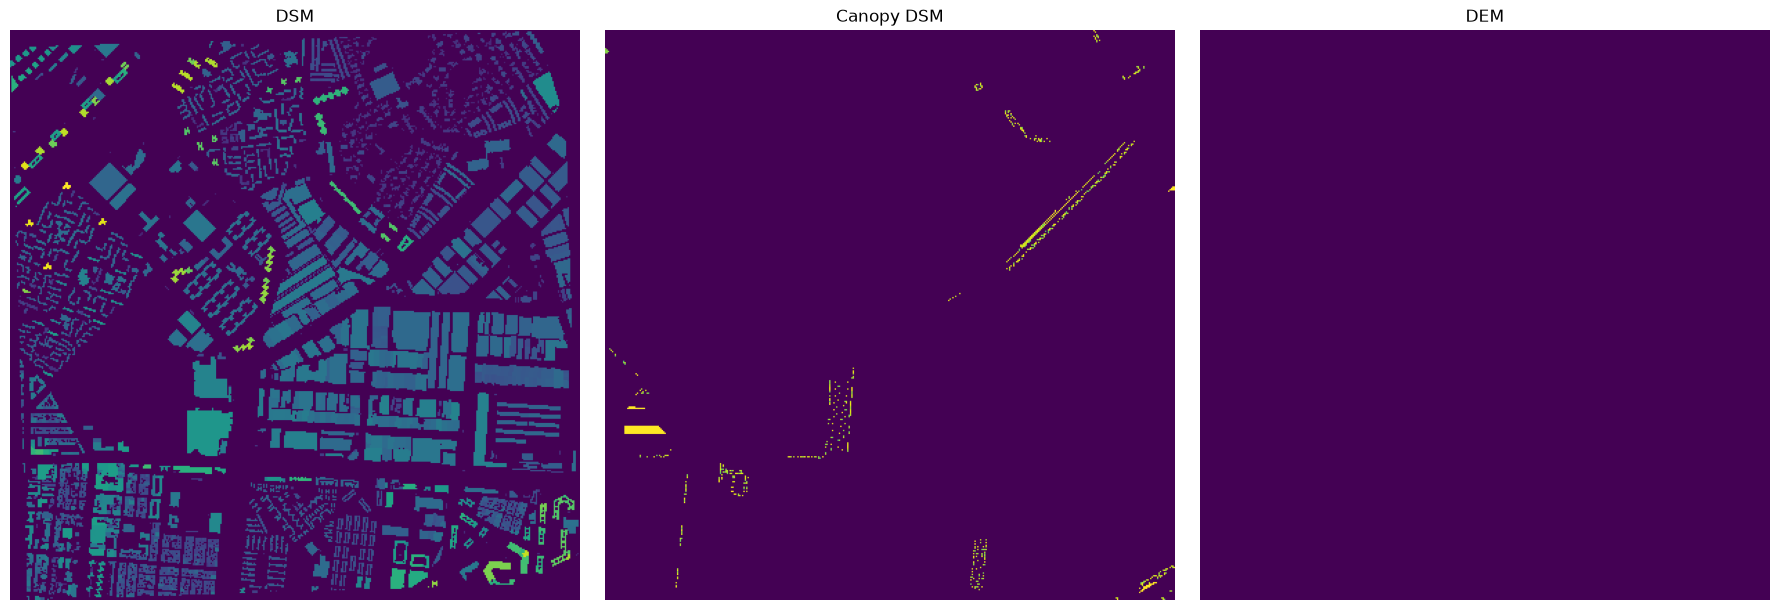

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(dsm, origin="lower")
axes[0].set_title("DSM")

axes[1].imshow(cdsm, origin="lower")
axes[1].set_title("Canopy DSM")

axes[2].imshow(dem, origin="lower")
axes[2].set_title("DEM")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [6]:
from pyproj import Transformer

bounds = vox.voxels.meta.bounds
minlon, minlat, maxlon, maxlat = bounds

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:25830",
    always_xy=True
)

xmin, ymin = transformer.transform(minlon, minlat)
xmax, ymax = transformer.transform(maxlon, maxlat)

print(xmin, ymin, xmax, ymax)

237173.53465099988 4141490.6968218554 239298.8809287973 4143486.7649837327


In [7]:
from rasterio.transform import from_bounds

height, width = dsm.shape

transform = from_bounds(
    xmin,
    ymin,
    xmax,
    ymax,
    width,
    height
)

transform

Affine(5.158607470382088, 0.0, 237173.53465099988,
       0.0, -4.844825635624606, 4143486.7649837327)

In [8]:
import rasterio
import numpy as np

def write_geotiff(path, array, transform, crs="EPSG:25830"):
    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype=array.dtype,
        crs=crs,
        transform=transform,
        compress="lzw"
    ) as dst:
        dst.write(array, 1)

In [9]:
write_geotiff(
    SOLWEIG_INPUTS / "dsm.tif",
    dsm.astype("float32"),
    transform
)

write_geotiff(
    SOLWEIG_INPUTS / "cdsm.tif",
    cdsm.astype("float32"),
    transform
)

write_geotiff(
    SOLWEIG_INPUTS / "dem.tif",
    dem.astype("float32"),
    transform
)

In [10]:
for name in ["dsm.tif", "cdsm.tif", "dem.tif"]:
    path = SOLWEIG_INPUTS / name

    with rasterio.open(path) as src:
        print(
            name,
            src.crs,
            src.shape,
            src.res,
            src.bounds
        )

dsm.tif EPSG:25830 (412, 412) (5.158607470382088, 4.844825635624606) BoundingBox(left=237173.53465099988, bottom=4141490.6968218554, right=239298.8809287973, top=4143486.7649837327)
cdsm.tif EPSG:25830 (412, 412) (5.158607470382088, 4.844825635624606) BoundingBox(left=237173.53465099988, bottom=4141490.6968218554, right=239298.8809287973, top=4143486.7649837327)
dem.tif EPSG:25830 (412, 412) (5.158607470382088, 4.844825635624606) BoundingBox(left=237173.53465099988, bottom=4141490.6968218554, right=239298.8809287973, top=4143486.7649837327)


In [11]:
import numpy as np
import rasterio

from rasterio.transform import from_bounds
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
)

bounds = vox.voxels.meta.bounds
minlon, minlat, maxlon, maxlat = bounds

height, width = dsm.shape

src_transform = from_bounds(
    minlon,
    minlat,
    maxlon,
    maxlat,
    width,
    height
)

src_crs = "EPSG:4326"
dst_crs = "EPSG:25830"

In [12]:
dst_transform, dst_width, dst_height = calculate_default_transform(
    src_crs,
    dst_crs,
    width,
    height,
    minlon,
    minlat,
    maxlon,
    maxlat,
    resolution=5
)

print(dst_width, dst_height)
print(dst_transform)

426 426
| 5.00, 0.00, 237173.53|
| 0.00,-5.00, 4143551.41|
| 0.00, 0.00, 1.00|


In [13]:
def reproject_to_5m(array):
    destination = np.zeros(
        (dst_height, dst_width),
        dtype=np.float32
    )

    # VoxCity north coordinate increases upward;
    # rasterio expects row 0 to be the northern/top row.
    source = np.flipud(array).astype(np.float32)

    reproject(
        source=source,
        destination=destination,
        src_transform=src_transform,
        src_crs=src_crs,
        dst_transform=dst_transform,
        dst_crs=dst_crs,
        resampling=Resampling.bilinear,
    )

    return destination

In [14]:
dsm_5m = reproject_to_5m(dsm)
cdsm_5m = reproject_to_5m(cdsm)
dem_5m = reproject_to_5m(dem)

In [15]:
def write_projected_geotiff(path, array):
    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype="float32",
        crs=dst_crs,
        transform=dst_transform,
        compress="lzw"
    ) as dst:
        dst.write(array.astype("float32"), 1)

In [16]:
write_projected_geotiff(
    SOLWEIG_INPUTS / "dsm.tif",
    dsm_5m
)

write_projected_geotiff(
    SOLWEIG_INPUTS / "cdsm.tif",
    cdsm_5m
)

write_projected_geotiff(
    SOLWEIG_INPUTS / "dem.tif",
    dem_5m
)

In [17]:
for name in [
    "dsm.tif",
    "cdsm.tif",
    "dem.tif"
]:
    path = SOLWEIG_INPUTS / name

    with rasterio.open(path) as src:
        print(
            name,
            "CRS:", src.crs,
            "shape:", src.shape,
            "resolution:", src.res,
            "bounds:", src.bounds
        )

dsm.tif CRS: EPSG:25830 shape: (426, 426) resolution: (5.0, 5.0) bounds: BoundingBox(left=237173.53465099988, bottom=4141421.4097209056, right=239303.53465099988, top=4143551.4097209056)
cdsm.tif CRS: EPSG:25830 shape: (426, 426) resolution: (5.0, 5.0) bounds: BoundingBox(left=237173.53465099988, bottom=4141421.4097209056, right=239303.53465099988, top=4143551.4097209056)
dem.tif CRS: EPSG:25830 shape: (426, 426) resolution: (5.0, 5.0) bounds: BoundingBox(left=237173.53465099988, bottom=4141421.4097209056, right=239303.53465099988, top=4143551.4097209056)


In [18]:
import rasterio
import numpy as np

for name in ["dsm.tif", "cdsm.tif", "dem.tif"]:
    path = SOLWEIG_INPUTS / name

    with rasterio.open(path) as src:
        arr = src.read(1)

        print(
            name,
            "min:", np.nanmin(arr),
            "mean:", np.nanmean(arr),
            "max:", np.nanmax(arr)
        )

dsm.tif min: 0.0 mean: 3.729568 max: 40.4
cdsm.tif min: 0.0 mean: 0.050034314 max: 10.0
dem.tif min: 0.0 mean: 0.0 max: 0.0
